# PHM 2026 — understand one real sample

A beginner-friendly **dataset** walkthrough, not a new PatchTST experiment. Follow [overview](#overview) → [one sample](#sample) → [sensor evidence](#sensors) → [image evidence](#images) → [shapes and code](#trace).

PHM records a gear test rig through vibration, operating context, condition indicators and inspection photographs. A **run** is a test period; a ZIP **archive** contains many HDF5 measurement files called **members**. A **channel** is one measured quantity. A **modality** is a type of observation. A **feature** summarizes measurements numerically. An **array** is a block of numbers; its **shape** gives the sizes of its dimensions.

One HDF5 member is not a whole run and is not automatically a labelled model example. A historical run-level branch collects many member-level feature rows into one run sequence. We use one actual saved member row and show its place in that sequence.

**Availability:** the configured raw root may be absent. The user approved using saved evidence. We distinguish saved inventory metadata, saved numerical features and retained annotated images from newly decoded raw data. No fabricated waveform replaces a missing raw recording.

**Labels:** run number and lifecycle stage are not health labels. Organizer ground-truth damage labels are not available in this pipeline. Historical image-derived targets are provisional heuristics, not verified damage truth.

In [1]:
DOMAIN = 'phm2026'
EXPERIMENT = 'EXP-B'
RUN_NUMBER = 1
MEMBER_NAME = None  # None = earliest saved timestamp; tie-break by member name
from pathlib import Path
import os, sys, json, importlib.util
from datetime import datetime, timezone
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'REPO_MAP.md').exists())
sys.dont_write_bytecode = True
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT/'tutorials/EDA'))
from reassemble_support import identity, reference
if 'EDA_OUTPUT' in os.environ:
    OUT = Path(os.environ['EDA_OUTPUT'])
else:
    OUT = ROOT/'runs'/DOMAIN/(datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')+'-dataset-eda')
    OUT.mkdir(parents=True, exist_ok=False)
    (OUT/'.gitignore').write_text('*\n')
for name in ['figures','media','tables','reports','manifests','config','runtime']:
    (OUT/name).mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(OUT/'runtime/matplotlib')
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, Audio
plt.rcParams.update({'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
inputs = {}; warnings = []; shapes = []
def track(path):
    inputs[os.path.relpath(path,ROOT)] = identity(path,ROOT,Path(path).stat().st_size < 20*1024**2)
def table(frame): display(frame.style.hide(axis='index'))
def figure(fig,name):
    path=OUT/'figures'/name
    fig.savefig(path,dpi=120,bbox_inches='tight');plt.close(fig)
    display(Image(filename=str(path)))
def shape(stage,array,meaning):
    shapes.append(dict(stage=stage,shape=str(array.shape),dtype=str(array.dtype),dimensions=meaning,evidence='Measured from loaded array'))
def module(name,path):
    spec=importlib.util.spec_from_file_location(name,path);m=importlib.util.module_from_spec(spec)
    sys.modules[name]=m;spec.loader.exec_module(m);track(path);return m

<a id="overview"></a>
## 1. What is available?

The overview uses the pinned dataset-description source identities in `configs/experiments/phm2026_dataset_description.yaml`. Scope is EXP-A runs 1–5, EXP-B runs 1–7 and EXP-F runs 1–8. The saved spectral feature bank is specifically `tutorials/patchtst_freq_baseline/features/per_run`; it is separate from other PHM feature pipelines. Counts below are saved-evidence counts, not a new raw-data audit.

role,path,exists now
Configured raw root,gtc-data-experiment,False
Saved sensor profile,runs/phm2026_dataset_description/20260813T212734652736Z-f7c665fd/tables/sensor_profile.parquet,True
Saved feature bank,tutorials/patchtst_freq_baseline/features/per_run,True


file,experiment,run,saved_member_rows
EXP-A_run1.parquet,EXP-A,1,372
EXP-A_run2.parquet,EXP-A,2,372
EXP-A_run3.parquet,EXP-A,3,371
EXP-A_run4.parquet,EXP-A,4,341
EXP-A_run5.parquet,EXP-A,5,377
EXP-B_run1.parquet,EXP-B,1,372
EXP-B_run2.parquet,EXP-B,2,372
EXP-B_run3.parquet,EXP-B,3,371
EXP-B_run4.parquet,EXP-B,4,372
EXP-B_run5.parquet,EXP-B,5,371


Saved sensor profile: channel records = 27165 ; distinct profiled members = 745
Saved image profile rows = 1311 ; saved run feature tables = 20


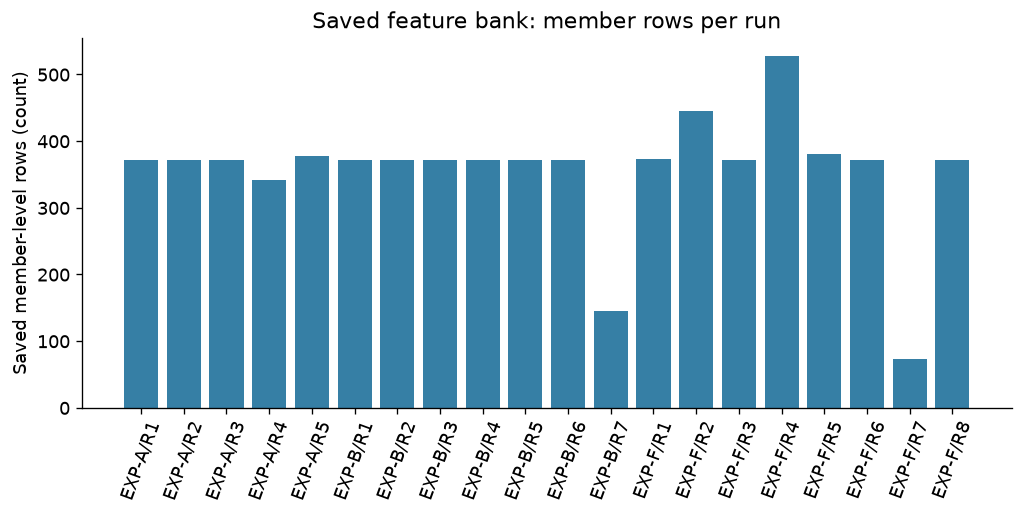

In [2]:
import yaml
config_path=ROOT/'configs/datasets/phm2026.yaml'
description_path=ROOT/'configs/experiments/phm2026_dataset_description.yaml'
config=yaml.safe_load(config_path.read_text());description=yaml.safe_load(description_path.read_text())
track(config_path);track(description_path)
RAW=Path(os.environ.get('PHM_DATA_ROOT',str(ROOT/config['dataset']['data_root'])))
# Resolve pinned report paths by their declared run IDs, without mixing runs.
def pinned(name):
    def seek(obj):
        if isinstance(obj,dict):
            if name in obj and isinstance(obj[name],dict) and 'directory' in obj[name]:return obj[name]
            for value in obj.values():
                hit=seek(value)
                if hit:return hit
        return None
    entry=seek(description)
    assert entry is not None,name
    return ROOT/entry['directory']
SENSOR=pinned('sensor_profile')/'tables/sensor_profile.parquet'
IMAGES=pinned('image_profile')/'tables/image_profile.parquet'
sensors=pd.read_parquet(SENSOR);images=pd.read_parquet(IMAGES);track(SENSOR);track(IMAGES)
FEATURES=ROOT/'tutorials/patchtst_freq_baseline/features/per_run'
feature_paths=sorted(FEATURES.glob('*.parquet'))
summary=[]
for p in feature_paths:
    frame=pd.read_parquet(p,columns=['experiment','run','member_name'])
    summary.append({'file':p.name,'experiment':frame.experiment.iloc[0],'run':int(frame.run.iloc[0]),'saved_member_rows':len(frame)})
summary=pd.DataFrame(summary)
table(pd.DataFrame([['Configured raw root',config['dataset']['data_root'],RAW.exists()],['Saved sensor profile',str(SENSOR.relative_to(ROOT)),SENSOR.exists()],['Saved feature bank',str(FEATURES.relative_to(ROOT)),FEATURES.exists()]],columns=['role','path','exists now']))
if not RAW.exists():warnings.append('Raw PHM archives unavailable at configured root; raw waveforms and new raw-image decoding are unavailable. Saved evidence is used.')
table(summary)
print('Saved sensor profile: channel records =',len(sensors),'; distinct profiled members =',sensors.hdf5_member_id.nunique())
print('Saved image profile rows =',len(images),'; saved run feature tables =',len(summary))
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(summary.experiment+'/R'+summary.run.astype(str),summary.saved_member_rows,color='#367fa5')
ax.tick_params(axis='x',rotation=70);ax.set(title='Saved feature bank: member rows per run',ylabel='Saved member-level rows (count)')
figure(fig,'saved_population.png')

**What you are seeing:** the number of existing numerical member rows in each run table. These rows represent repeated measurements, not independent labelled runs.

**Why it matters:** 20 run tables and thousands of member rows are different population sizes. EXP-A Run 2 also has a reported 311-file overlap warning with Run 1; this notebook preserves the existing rows and performs no deduplication.

<a id="sample"></a>
## 2. Choose one real member and inspect its identity

Default selection is the earliest timestamp in fixed EXP-B Run 1, with a member-name tie-break. This is a descriptive choice independent of target values or predictions. The full identity includes experiment, authoritative run, outer archive and internal member. Internal filename run tokens can disagree with outer run identity; they do not replace it.

In [3]:
feature_path=FEATURES/f'{EXPERIMENT}_run{RUN_NUMBER}.parquet'
frame=pd.read_parquet(feature_path).sort_values(['wf_start_time','member_name'],kind='stable').reset_index(drop=True);track(feature_path)
assert frame.experiment.eq(EXPERIMENT).all() and frame.run.eq(RUN_NUMBER).all()
chosen=frame.iloc[0] if MEMBER_NAME is None else frame.loc[frame.member_name.eq(MEMBER_NAME)].iloc[0]
sample_identity={'experiment':EXPERIMENT,'run':RUN_NUMBER,'archive':f'high_frequency/EXP {EXPERIMENT[-1]}/Exp-{EXPERIMENT[-1]}_HDF5_Run-{RUN_NUMBER}.zip','member':chosen.member_name,'timestamp':str(chosen.wf_start_time)}
table(pd.DataFrame(sample_identity.items(),columns=['field','value']))
# Stream the saved build log until the exact composite identity is found.
log=ROOT/'tutorials/patchtst_freq_baseline/features/build_log.jsonl';track(log)
evidence=None
with log.open() as stream:
    for line in stream:
        item=json.loads(line)
        if item['experiment']==EXPERIMENT and int(item['run'])==RUN_NUMBER and item['member_name']==chosen.member_name:
            evidence=item;break
assert evidence is not None,'Selected member must exist in its own feature-build provenance'
table(pd.DataFrame([(k,str(v)) for k,v in evidence.items()],columns=['saved extraction evidence','value']))
# A physical schema example from the same experiment/run, if actually profiled.
profile=sensors[(sensors.experiment==EXPERIMENT)&(sensors.run==RUN_NUMBER)&sensors.hdf5_member_path.eq(chosen.member_name)]
if len(profile):table(profile[['hdf5_path','shape_json','dtype','unit','sampling_rate_hz']])
else:display(Markdown('> This member has no matching row in the pinned structural sensor profile. Its raw HDF5 structure is unavailable for direct inspection here; the build log above is retained extraction evidence, not a new payload read.'))

field,value
experiment,EXP-B
run,1
archive,high_frequency/EXP B/Exp-B_HDF5_Run-1.zip
member,Run-1/Dyno Gear303Run1_00000.hdf5
timestamp,2024-10-04T13:10:38.273325+00:00


saved extraction evidence,value
experiment,EXP-B
run,1
member_name,Run-1/Dyno Gear303Run1_00000.hdf5
wf_start_time,2024-10-04T13:10:38.273325+00:00
duration_seconds,"{'Accel 1': 25.249999999999883, 'Accel 2': 25.249999999999883}"
sample_count,"{'Accel 1': 2585600, 'Accel 2': 2585600}"
sample_rate_hz,"{'Accel 1': 102400.00000000048, 'Accel 2': 102400.00000000048}"
channel_errors,{}
exclusion_reason,None


> This member has no matching row in the pinned structural sensor profile. Its raw HDF5 structure is unavailable for direct inspection here; the build log above is retained extraction evidence, not a new payload read.

The physical layout described by `tutorials/patchtst_freq_baseline/features.py:extract_member_features` reads `Vibration/Accel 1` and `Vibration/Accel 2`, their `wf_start_time` and sampling attributes. Other PHM containers can contain `/Context`, `/CI` or `/CI_4s`, `/Oil` and `/Environment`; see `configs/datasets/phm2026.yaml`. This is source/config evidence, not a claim that all groups occur in this inaccessible member.

A **timestamp** records when an observation starts. The saved `wf_start_time` preserves UTC. We do not use ZIP ordering as a clock. The saved build-log duration and sampling rate are retained metadata; the raw waveform shape and dtype are not newly measured.

<a id="sensors"></a>
## 3. What do this sample’s saved measurements look like?

The saved feature extractor summarizes each of two accelerometer signals into frequency-band values and broad summaries. **RMS** is root mean square, describing signal magnitude; crest factor compares the peak magnitude with RMS; spectral centroid summarizes the frequency distribution. These features are not the original waveform.

feature,actual value
accel1_band00_log1p_energy,0.000000
accel1_band01_log1p_energy,0.000000
accel1_band02_log1p_energy,0.000000
accel1_band03_log1p_energy,0.000000
accel1_band04_log1p_energy,0.000001
accel1_band05_log1p_energy,0.000001
accel1_band06_log1p_energy,0.000003
accel1_band07_log1p_energy,0.000003


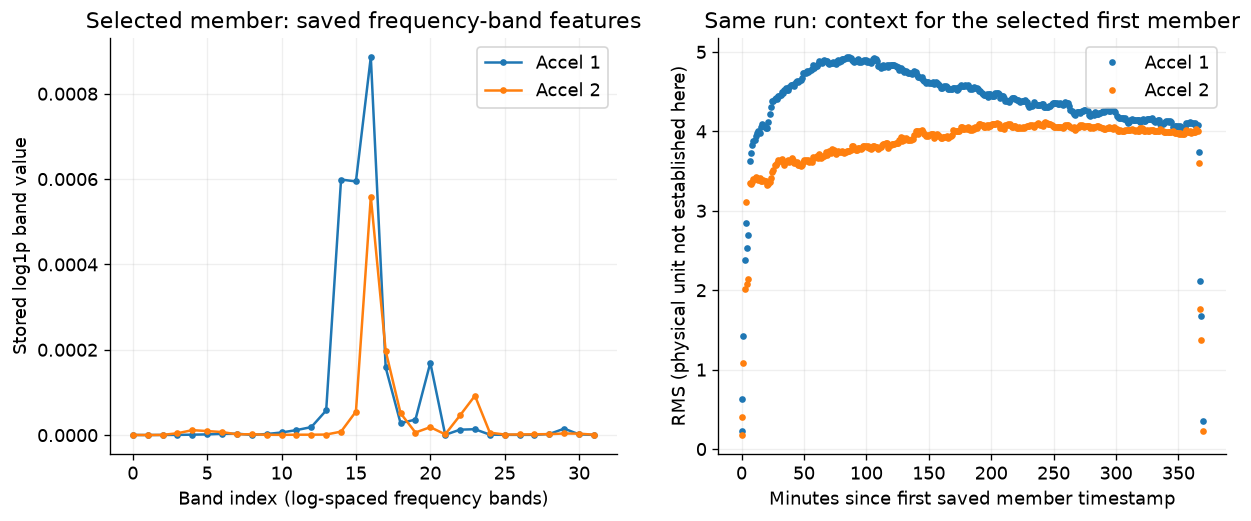

Nonfinite values in selected vector: 0
Saved channel-missingness flags: {'accel1_missing': 0.0, 'accel2_missing': 0.0}


In [4]:
columns=[x for x in frame.columns if x not in ['experiment','run','member_name','wf_start_time']]
vector=chosen[columns].to_numpy(dtype=np.float64)
sequence=frame[columns].to_numpy(dtype=np.float64)
shape('One actual saved member feature row',vector,'feature components')
shape('Run sequence from the same saved bank',sequence,'member positions in timestamp order × features')
table(pd.DataFrame({'feature':columns[:8],'actual value':vector[:8]}))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for channel in [1,2]:
    band_columns=[f'accel{channel}_band{i:02d}_log1p_energy' for i in range(32)]
    axes[0].plot(range(32),chosen[band_columns].to_numpy(dtype=float),'.-',label=f'Accel {channel}')
    stamp=pd.to_datetime(frame.wf_start_time,utc=True)
    axes[1].plot((stamp-stamp.iloc[0]).dt.total_seconds()/60,frame[f'accel{channel}_rms'],'.',label=f'Accel {channel}')
axes[0].set(title='Selected member: saved frequency-band features',xlabel='Band index (log-spaced frequency bands)',ylabel='Stored log1p band value')
axes[1].set(title='Same run: context for the selected first member',xlabel='Minutes since first saved member timestamp',ylabel='RMS (physical unit not established here)')
for ax in axes:ax.legend();ax.grid(alpha=.2)
figure(fig,'member_features.png')
print('Nonfinite values in selected vector:',int((~np.isfinite(vector)).sum()))
print('Saved channel-missingness flags:',chosen[['accel1_missing','accel2_missing']].to_dict())

**What you are seeing:** the two accelerometer feature profiles for one real member, plus member-level RMS over its run. Points in the run plot avoid suggesting continuous measurements between members.

**Why it matters:** a feature row compresses many raw observations. The horizontal band index is not time, and neither plot is a newly decoded raw vibration waveform. Frequency processing is the historical extractor’s behavior; no formulas are corrected or features regenerated here.

<a id="images"></a>
## 4. A retained inspection image from the same run

PHM photos are inspection observations, not synchronized video frames for the vibration member. The example below is selected lexicographically from the same experiment/run with a retained overlay. It is **not** asserted to correspond to the exact measurement timestamp.

The image target pipeline’s retained overlay contains heuristic markings. These are derived annotations, **not organizer labels or verified object detections**. The underlying picture comes from the dataset; we create no synthetic imagery.

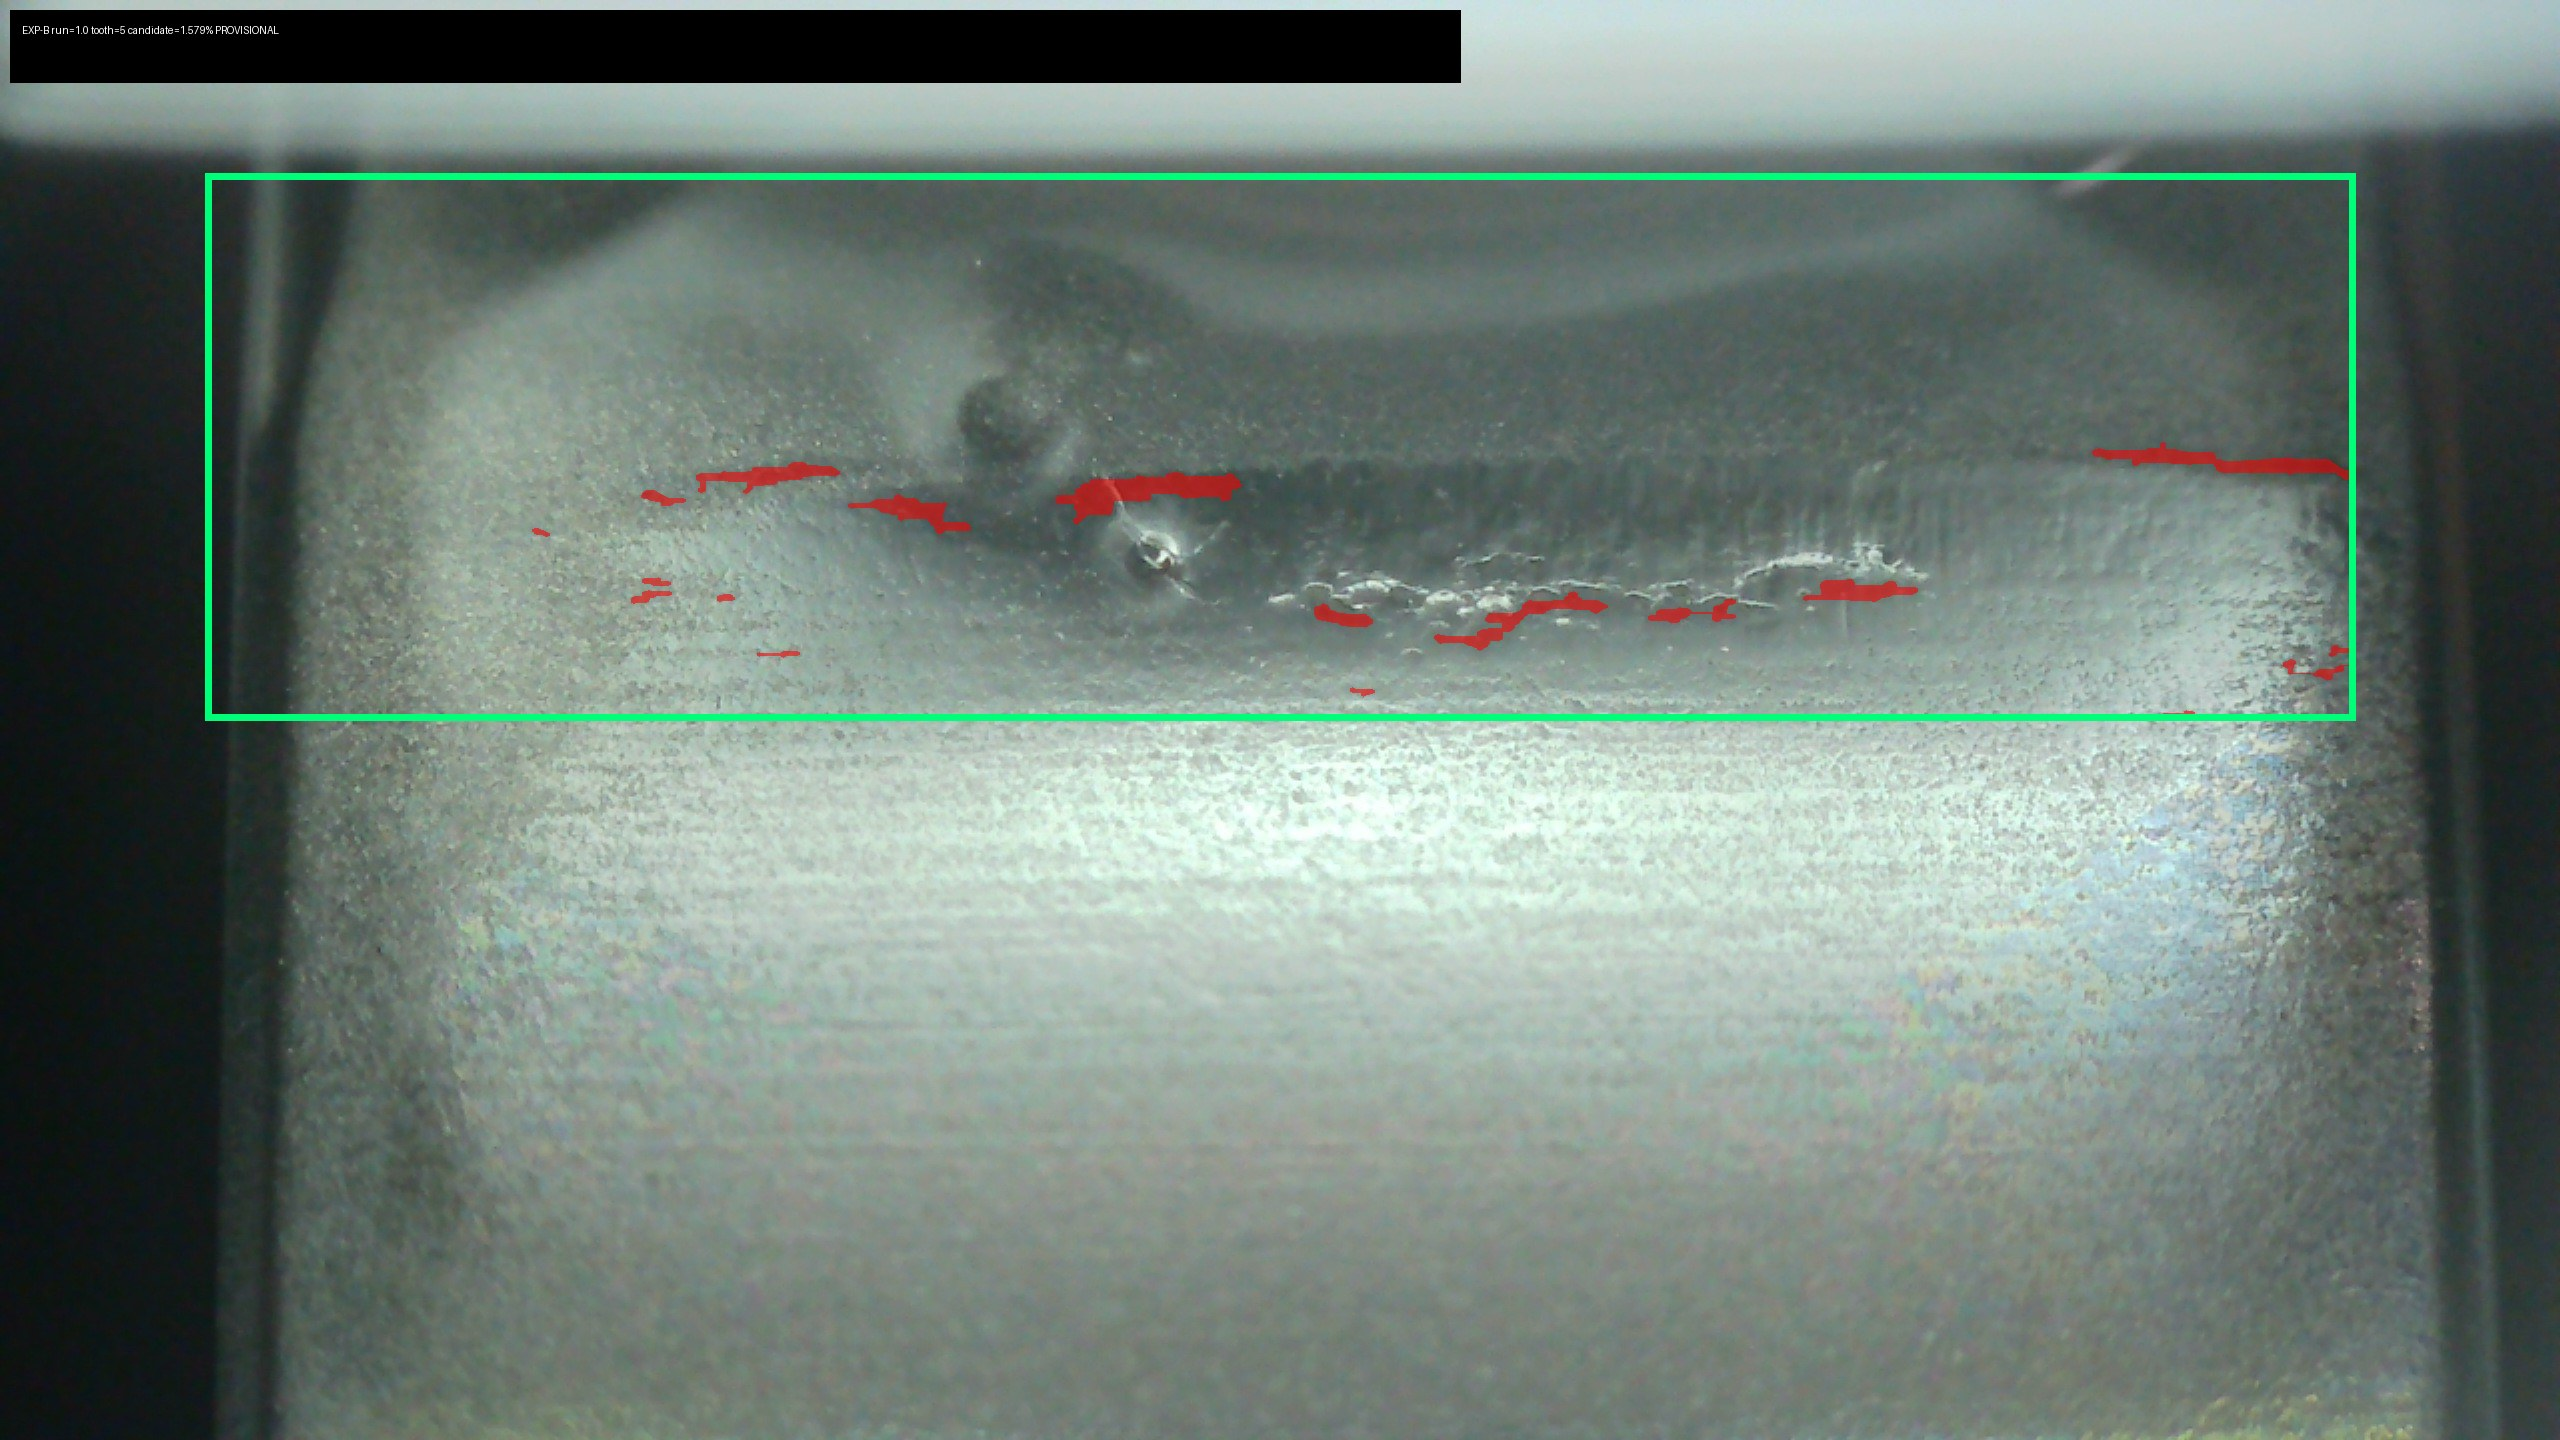

identity/evidence,value
Image ID,image_profile_bcaeb1ae30128ed5bee08913445b88929741343f5335707c50960ea92ae2c6d4
Original source,photos/EXP-B/Exp-B_Photos_Run 1.zip!Run 1/All Teeth/Tooth 05.jpg
Raw image shape from saved header,"[1440,2560,3]"
Preview file,runs/phm2026_image_target/20260814T012054997053Z-e195f6d9/overlays/image_profile_bcaeb1ae30128ed5bee08913445b88929741343f5335707c50960ea92ae2c6d4.jpg


In [5]:
from PIL import Image as PILImage
OVERLAYS=ROOT/'runs/phm2026_image_target/20260814T012054997053Z-e195f6d9/overlays'
photo=None
for candidate in images[(images.experiment==EXPERIMENT)&(images.run==RUN_NUMBER)].sort_values('source_relative_path').itertuples():
    path=OVERLAYS/(candidate.image_id+'.jpg')
    if path.exists():photo=(candidate,path);break
if photo:
    record,path=photo;track(path)
    with PILImage.open(path) as im:rgb=np.asarray(im.convert('RGB'))
    shape('Retained annotated preview (not raw image)',rgb,'preview height × preview width × RGB channels')
    display(Image(filename=str(path),width=800))
    table(pd.DataFrame([['Image ID',record.image_id],['Original source',record.source_relative_path],['Raw image shape from saved header',record.shape_hwc_json],['Preview file',str(path.relative_to(ROOT))]],columns=['identity/evidence','value']))
else:
    warnings.append('No matching retained image preview available. No substitute image used.')
    display(Markdown('> No matching local preview is available.'))

**What you are seeing:** a retained annotated image associated with the selected run, with original source identity preserved.

**Why it matters:** shared run membership is weaker than synchronized observation. An image-derived target or overlay must not be presented as ground-truth damage or as the exact visual counterpart of one minute of vibration.

<a id="trace"></a>
## 5. Shapes, repository trace and what remains unavailable

| Question | Actual location | Input → output |
|---|---|---|
| Which experiments/runs? | `configs/datasets/phm2026.yaml` | authoritative scope and raw root |
| How are archives read? | `src/phm2026/profiling/archive_io.py:materialize_archive_member` | bounded ZIP payload → temporary seekable file |
| Where is physical schema measured? | `src/phm2026/profiling/sensors.py` | HDF5 metadata → pinned sensor-profile rows |
| Where were these features extracted? | `tutorials/patchtst_freq_baseline/features.py:extract_member_features` | two accelerometers → member feature row |
| Where were they saved? | `tutorials/patchtst_freq_baseline/build_features.py:process_run` | per-member features → per-run Parquet + build log |
| What is a run-level model sample? | `tutorials/patchtst_freq_baseline/train.py:load_run_features`, `build_dataset` | timestamp-ordered member rows → one sequence per run |

The shapes below are measured from loaded saved arrays. The raw waveform, its direct HDF5 inspection and new raw-photo decoding remain unavailable at the configured root. No model batch, predictions or performance claims are invented. This completes the available saved-evidence walkthrough.

In [6]:
for relative in ['tutorials/patchtst_freq_baseline/features.py','tutorials/patchtst_freq_baseline/build_features.py','tutorials/patchtst_freq_baseline/train.py','src/phm2026/profiling/archive_io.py']:
    track(ROOT/relative)
(OUT/'config/selection.json').write_text(json.dumps({'experiment':EXPERIMENT,'run':RUN_NUMBER,'member':MEMBER_NAME,'raw_root':os.path.relpath(RAW,ROOT),'source_bank':str(FEATURES.relative_to(ROOT))},indent=2))
table(pd.DataFrame(shapes))
for relative,before in inputs.items():
    after=identity(ROOT/relative,ROOT)
    assert after['bytes']==before['bytes'] and after['mtime_ns']==before['mtime_ns'], relative
(OUT/'tables/shapes.json').write_text(json.dumps(shapes,indent=2))
(OUT/'manifests/inputs.json').write_text(json.dumps(list(inputs.values()),indent=2))
(OUT/'reports/verification.json').write_text(json.dumps({'inputs_metadata_unchanged':True,'sample':sample_identity,'warnings':warnings,'training_or_evaluation_run':False,'browser_playback_verified':False},indent=2))
display(Markdown('**Read-only checks passed.** Input size/mtime unchanged. No models trained or evaluated; no inventories, labels or feature banks regenerated.'))
for warning in warnings: display(Markdown('> '+warning))

stage,shape,dtype,dimensions,evidence
One actual saved member feature row,"(72,)",float64,feature components,Measured from loaded array
Run sequence from the same saved bank,"(372, 72)",float64,member positions in timestamp order × features,Measured from loaded array
Retained annotated preview (not raw image),"(1440, 2560, 3)",uint8,preview height × preview width × RGB channels,Measured from loaded array


**Read-only checks passed.** Input size/mtime unchanged. No models trained or evaluated; no inventories, labels or feature banks regenerated.

> Raw PHM archives unavailable at configured root; raw waveforms and new raw-image decoding are unavailable. Saved evidence is used.